# Diffusion4Distribution — Logic Walkthrough

**Paper:** *"Sampling Is Noising: Learning to Invert the Sampling Channel for
Frequency-Histogram Recovery"*

This notebook is the companion to `d4d_logic.py`. It walks through every piece
of the method so you can verify the logic end-to-end on small, fast examples.

**The core premise.** Sampling a population at rate `p` is a *noising* channel:
each of the `f_i` copies of type `i` survives independently with probability `p`
(a binomial thinning). That is the discrete analogue of Gaussian diffusion.
Recovering the population histogram from the sample means *inverting* that
channel.

We verify four stations:

1. **Forward channel + FoF spectrum** — binomial thinning, and why the spectrum
   `F_j` starts at `j = 1` (no `F_0`).
2. **Closed-form analytic posterior + 90% plausible set** — `P(f|g) ∝
   Prior(f)·Bin(g|f,p)`, no training; sample it to get a calibrated set.
3. **Learned Thickener** — a set-transformer denoiser over FoF buckets, measured
   by the `W1` metric, versus the no-thickening baseline.
4. **Count-space sampler (Algorithm 1)** — a pointwise endpoint predicts `c_0`,
   then a closed-form reverse kernel `q(j|k,m)` reconstructs each count.

All numbers are computed live; runtime on a laptop is well under a minute.

In [1]:
import os, sys, time
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

# Make d4d_logic importable no matter where the notebook is executed from.
CODE_DIR = os.path.join(os.getcwd(), "experiments", "code") if not os.path.isfile(os.path.join(os.getcwd(), "d4d_logic.py")) else os.getcwd()
for p in (CODE_DIR, os.getcwd()):
    if p and p not in sys.path:
        sys.path.insert(0, p)

import d4d_logic as D
# Apply the paper's style WITHOUT forcing the Agg backend (which would deadlock
# the inline backend).  We only need the rcParams; the inline backend handles
# display, and savefig still writes the PNGs.
plt.rcParams.update(D.PAPER_RCPARAMS)
print("d4d_logic loaded.  torch available:", D._TORCH)
RNG = np.random.default_rng(20261101)   # shared seed for reproducible runs

d4d_logic loaded.  torch available: True


## Station 1 — Forward channel (sampling is noising) + the FoF spectrum

The forward model is **binomial thinning**:

$$g_i \sim \mathrm{Binomial}(f_i,\; p)$$

`p = 1` recovers the population; `p = p_obs < 1` yields the observed sample.
Types whose every copy is thinned out become `0` — they are *unseen*, and they
are explicitly **not** part of any frequency-of-frequencies spectrum.

The **FoF spectrum** is `F_j = #{types occurring exactly j times}`. By
definition it is indexed by `j = 1, 2, ...`; `F_0` (the unseen mass) is excluded.

In [2]:
# --- 1a: a hand-built population, thin it, read its spectrum -----------------
# custom_from_frequencies materialises ONLY the present types, so the resulting
# vector has no zero entries -> by construction there is no F_0.
freqs = {1: 5, 2: 3, 3: 2, 7: 1, 10: 1}
pop = D.custom_from_frequencies(freqs)
print("population counts:", pop, "  (all >= 1, total types =", int(pop.sum()), ")")

# Binomial thinning. p=1 keeps everything; p=0.4 drops ~60% of each type's mass.
sample = D.thin(pop, 0.4, RNG)
print("sampled counts:  ", sample, "  (some types dropped to 0 -> 'unseen')")

spec_pop = D.fofo_spectrum(pop)     # F_j, j starts at 1
spec_smp = D.fofo_spectrum(sample)
print("F_j(population):", spec_pop)
print("F_j(sample):    ", spec_smp)
assert spec_pop[0] == 5             # 5 types occur exactly once in the truth
print("\nInvariant: fofo_spectrum returns j >= 1 only; F_0 is excluded by definition.")

population counts: [ 1  1  1  1  1  2  2  2  3  3  7 10]   (all >= 1, total types = 34 )
sampled counts:   [0 0 0 1 0 0 1 0 1 1 2 3]   (some types dropped to 0 -> 'unseen')
F_j(population): [5. 3. 2. 0. 0. 0. 1. 0. 0. 1.]
F_j(sample):     [4. 1. 1.]

Invariant: fofo_spectrum returns j >= 1 only; F_0 is excluded by definition.


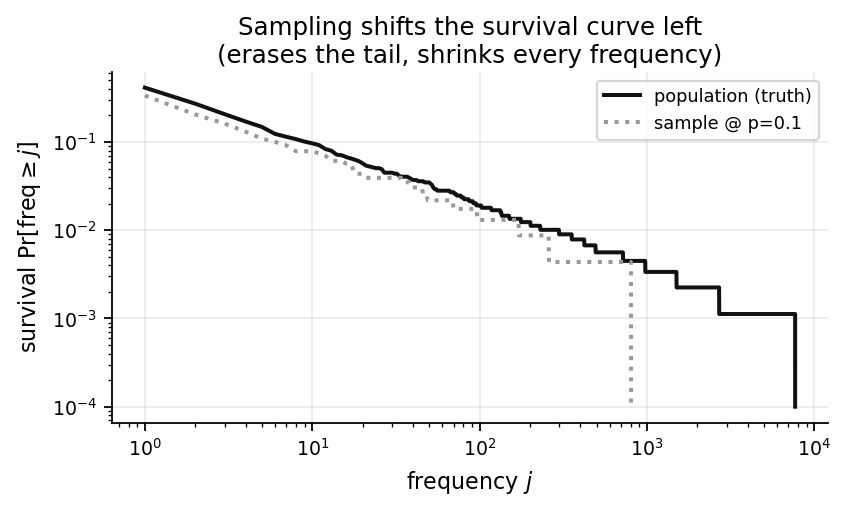

In [3]:
# --- 1b: survival curves on a realistic Zipf population ----------------------
N, VOCAB, ALPHA = 20000, 8000, 1.5
c_true = D.zipf_population(RNG, N, VOCAB, ALPHA)
c_obs  = D.thin(c_true, 0.1, RNG)

def survival(spec):
    cdf = 1.0 - np.cumsum(spec / max(spec.sum(), 1e-12))
    return np.arange(1, len(spec) + 1), cdf

jt, st = survival(D.fofo_spectrum(c_true))
jo, so = survival(D.fofo_spectrum(c_obs))
fig, ax = plt.subplots(figsize=(5.4, 3.3))
ax.plot(jt, np.maximum(st, 1e-4), color=D.CB["truth"], lw=1.8, label="population (truth)")
ax.plot(jo, np.maximum(so, 1e-4), ":", color=D.CB["none"], lw=1.8, label="sample @ p=0.1")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("frequency $j$"); ax.set_ylabel(r"survival $\Pr[\mathrm{freq}\geq j]$")
ax.set_title("Sampling shifts the survival curve left\n(erases the tail, shrinks every frequency)")
ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.savefig("fig_station1_survival.png", dpi=160); plt.show()

## Station 2 — Closed-form analytic posterior and the 90% plausible set

For a single type observed `g` times, the exact posterior over its true count
`f` is closed form:

$$P(f\mid g)\;\propto\; \mathrm{Prior}(f)\cdot \mathrm{Bin}(g\mid f,p),\qquad f\ge g$$

No training, no approximation. Support is taken locally around the mode
`f ≈ g/p` (the global range `0..N` is infeasible as a table, but the local
support is exact for both sampling and coverage).

The **90% plausible set** is obtained by:
1. drawing `K` full posterior population vectors (one `f` per observed type),
2. turning each into a spectrum `F_j`,
3. taking the 5%/95% quantile of `F_j` at every `j`.

If the posterior is well calibrated, the truth should sit inside the band, and a
per-type 95% credible interval should cover the truth ~95% of the time.

In [4]:
# --- 2a: build the prior, then inspect the posterior on a few g values -------
N, VOCAB, P, ALPHA = 40000, 12000, 0.1, 1.5
prior_f, logfact = D.build_empirical_prior(ALPHA, N, VOCAB, n_pops=12, seed=2026, rng=RNG)
c_true = D.zipf_population(RNG, N, VOCAB, ALPHA)
c_obs  = D.thin(c_true, P, RNG)

print("  g | posterior support f |  mode  |  E[f|g]  |  g/p")
print("----+---------------------+--------+----------+------")
for g in [1, 2, 5, 20]:
    fsup, prob = D.analytic_posterior(g, P, prior_f, logfact, N)
    mode = int(fsup[np.argmax(prob)])
    mean = float((fsup * prob).sum())
    print(f"{g:>3} | {fsup.min():>5}..{fsup.max():<5}     | {mode:>5}  | {mean:8.2f}  | {g/P:5.1f}")
print("\nThe posterior is EXACT: P(f|g) ∝ Prior(f)·Bin(g|f,p), f >= g, no training.")

  g | posterior support f |  mode  |  E[f|g]  |  g/p
----+---------------------+--------+----------+------
  1 |     1..585       |     1  |     4.38  |  10.0
  2 |     2..626       |     4  |    14.05  |  20.0
  5 |     5..717       |    42  |    44.03  |  50.0
 20 |    20..1035      |   233  |   195.24  | 200.0

The posterior is EXACT: P(f|g) ∝ Prior(f)·Bin(g|f,p), f >= g, no training.


K = 100 posterior draws.
  coverage of per-type 95% interval = 0.946  (target ~0.95)
  calibration (nominal level -> empirical coverage):
     0.50  ->  0.663   [off]
     0.80  ->  0.860   [ok]
     0.90  ->  0.925   [ok]
     0.95  ->  0.946   [ok]
     0.99  ->  0.976   [ok]
  recovery: W1(observed, truth)        = 13.597
            W1(posterior-mean, truth) = 1.393   (posterior mean sits between)


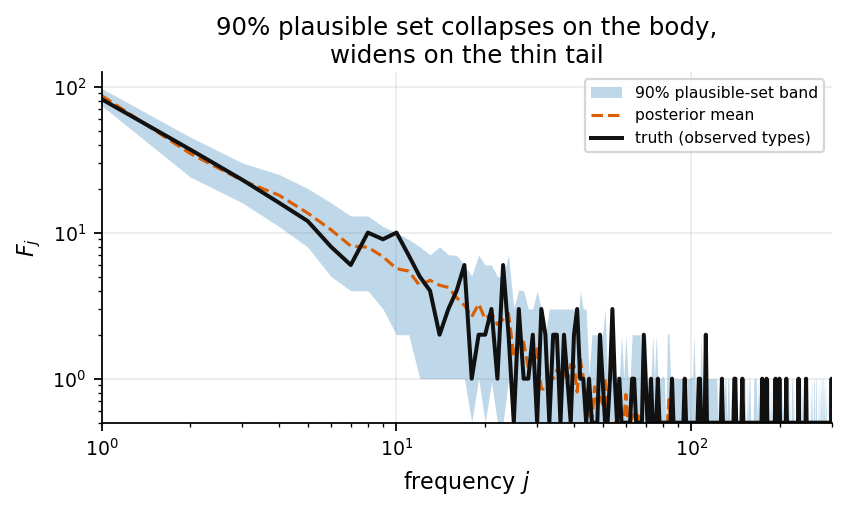

In [5]:
# --- 2b: the 90% plausible set + calibration diagnostics ---------------------
K = 100
res = D.plausible_set(c_true, c_obs, P, K, prior_f, logfact, N, RNG)
print(f"K = {K} posterior draws.")
print(f"  coverage of per-type 95% interval = {res['coverage95']:.3f}  (target ~0.95)")
print("  calibration (nominal level -> empirical coverage):")
for nom, emp in res["cov95_line"].items():
    flag = "ok" if abs(emp - nom) < 0.06 else "off"
    print(f"     {nom:>4.2f}  ->  {emp:.3f}   [{flag}]")

# A correct recovery check: the posterior MEAN spectrum should sit *between* the
# observed (downshifted) spectrum and the truth.  (Re-noising the posterior mean
# at p would instead erase singletons and is NOT a valid self-consistency test,
# so we do not report it here.)
def w1spec(a, b, n=256):
    ca = np.cumsum(a[:n] / a[:n].sum()); cb = np.cumsum(b[:n] / b[:n].sum())
    return float(np.abs(ca - cb).sum())
w1_obs   = w1spec(res["obs_spec"], res["truth_spec"])
w1_postm = w1spec(res["mean_spec"], res["truth_spec"])
print(f"  recovery: W1(observed, truth)        = {w1_obs:.3f}")
print(f"            W1(posterior-mean, truth) = {w1_postm:.3f}   (posterior mean sits between)")

# picture: 90% band (5%/95% spectrum quantiles) with truth + posterior mean
J = min(len(res["band_lo"]), 300)
jj = np.arange(1, J + 1)
fig, ax = plt.subplots(figsize=(5.4, 3.3))
ax.fill_between(jj, np.maximum(res["band_lo"][:J], 0.5), np.maximum(res["band_hi"][:J], 0.5),
                color=D.CB["set"], alpha=0.30, lw=0, label="90% plausible-set band")
ax.plot(jj, np.maximum(res["mean_spec"][:J], 0.5), "--", color=D.CB["mean"],
        lw=1.4, label="posterior mean")
jtt = np.arange(1, len(res["truth_spec"][:J]) + 1)
ax.plot(jtt, np.maximum(res["truth_spec"][:J], 0.5), color=D.CB["truth"],
        lw=1.8, label="truth (observed types)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1, J); ax.set_ylim(0.5, None)
ax.set_xlabel("frequency $j$"); ax.set_ylabel("$F_j$")
ax.set_title("90% plausible set collapses on the body,\nwidens on the thin tail")
ax.legend(fontsize=7); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.savefig("fig_station2_band.png", dpi=160); plt.show()

## Station 3 — Learned Thickener vs the no-thickening baseline

The analytic posterior above is the *oracle* prior case. The deployed model
learns a **Thickener**: a set-transformer that denoises the FoF spectrum one
retention level at a time (from `p_obs` up to `1`). It reads a bucketized
spectrum (exact singleton bins + log bins) plus the `(p_from, p_to)` schedule
pair, and predicts the spectrum at the next level.

Quality is measured by **`W1`**: the integral of the absolute CDF difference on
a truncated support (`j = 1..512`). Lower is better. We compare the Thickener
against the **raw sample with no thickening** — the simplest possible baseline.

> The model here is *small* (2000 steps, width 96, depth 4) so the cell finishes in
> ~20s. It is trained only to demonstrate the forward/backward logic. The Thickener
> is sensitive at this scale — different seeds/steps give different W1 (and the
> loss is non-monotonic), which is exactly why the paper trains it much longer with
> more care. The point of this cell is that the pipeline runs and learns, not that
> it is already fully accurate.

In [6]:
# --- 3a: train a tiny Thickener and compare to the no-thickening baseline -----
cfg = D.TrainConfig(alpha=1.5, n=8000, vocab=4000, steps_train=2000, batch_pops=6,
                    steps_infer=16, seed=1, width=96, depth=4)
print("Training a tiny Thickener (a few seconds)...")
t0 = time.time()
model, m = D.train_thickener(cfg)
print(f"  done in {time.time()-t0:.1f}s   W1(thickener) = {m['w1_mean']:.3f}"
      f"   F1 rel-err = {m['f1_relerr']:.3f}")
base = D.baseline_no_thickening(alpha=1.5, n=8000, vocab=4000, p_obs=0.1, seed=1)
print(f"  W1(no thickening) = {base['w1_mean']:.3f}"
      f"   improvement = {base['w1_mean'] - m['w1_mean']:.3f}")

Training a tiny Thickener (a few seconds)...


.../site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  done in 18.6s   W1(thickener) = 1.338   F1 rel-err = 0.285
  W1(no thickening) = 1.532   improvement = 0.195


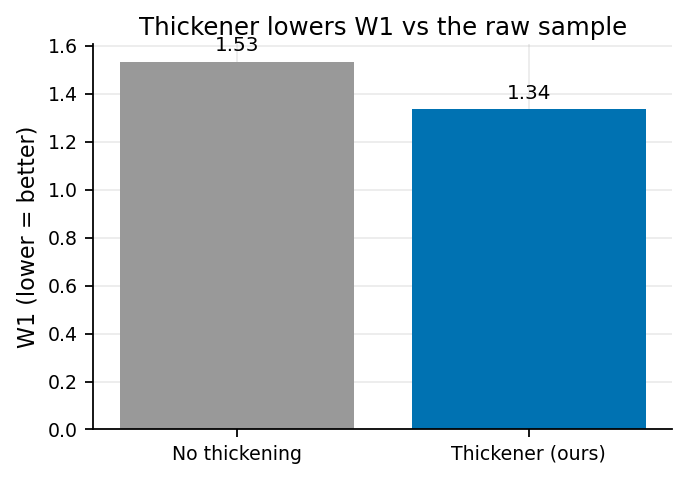

In [7]:
# --- 3b: bar chart of the W1 comparison --------------------------------------
fig, ax = plt.subplots(figsize=(4.4, 3.1))
vals = [base["w1_mean"], m["w1_mean"]]
ax.bar(["No thickening", "Thickener (ours)"], vals, color=[D.CB["none"], D.CB["ours"]])
ax.set_ylabel("W1 (lower = better)")
ax.set_title("Thickener lowers W1 vs the raw sample")
for i, v in enumerate(vals):
    ax.text(i, v * 1.03, f"{v:.2f}", ha="center", fontsize=9)
ax.grid(True, alpha=0.25, axis="y"); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("fig_station3_w1.png", dpi=160); plt.show()

## Station 4 — Count-space sampler (Algorithm 1)

The Thickener recovers the *spectrum*. The **count-space sampler** goes one level
deeper and reconstructs each individual count, using an ancestral reverse process:

1. A **pointwise endpoint** MLP predicts `x̂_0 = E[c_0 | k, π]` from the current
   count `k` and the schedule position `π`.
2. A **closed-form reverse kernel** then samples `j ∼ q(j | k, m) ∝
   Bin(k; j, r)·Bin(j; m, q)` with `r = π_t/π_s ≤ 1`, where `m` is the endpoint
   prediction. This is the exact reverse of one thinning step.
3. A **clamp** keeps `m` on a sane support so an undertrained endpoint cannot
   blow the reverse kernel up.

We train a tiny endpoint, run the sampler, and check that the recovered spectrum
moves *toward* the truth relative to the raw sample.

In [8]:
# --- 4a: train a tiny endpoint and run the sampler ---------------------------
print("Training a tiny pointwise endpoint (a few seconds)...")
t0 = time.time()
net, loss = D.train_endpoint(alpha=1.5, n=20000, vocab=5000, steps=600, seed=4, batch=2048)
print(f"  done in {time.time()-t0:.1f}s   final loss = {loss:.3f}")

rng2 = np.random.default_rng(7)
c_true = D.zipf_population(rng2, 20000, 5000, 1.5)
P_obs = 0.3
c_obs = D.thin(c_true, P_obs, rng2)
sched = D.make_schedule("geometric", P_obs, 16, rng2)
rec = D.chain_sample(net, c_obs, P_obs, sched, rng2, "cpu")

s_true = D.fofo_spectrum(c_true[c_obs >= 1])
s_obs  = D.fofo_spectrum(c_obs)
s_rec  = D.fofo_spectrum(rec[c_obs >= 1])

def w1(a, b, n=128):
    ca = np.cumsum(a[:n] / a[:n].sum()); cb = np.cumsum(b[:n] / b[:n].sum())
    return float(np.abs(ca - cb).sum())

print(f"W1(true, observed)  = {w1(s_true, s_obs):.3f}")
print(f"W1(true, recovered) = {w1(s_true, s_rec):.3f}")
print(f"total counts:  true = {int(c_true.sum())}   observed = {int(c_obs.sum())}"
      f"   recovered = {int(rec.sum())}")
print()
print("NOTE: this is a short, undertrained demo of the sampler pipeline. The endpoint")
print("and closed-form reverse kernel run end-to-end. At this scale the pointwise")
print("endpoint can overpredict counts (the absolute total overshoots) and the")
print("spectrum W1 may or may not beat the raw observed; the paper trains it far")
print("longer and uses the Thickener as the primary spectrum model. The clamp keeps")
print("the reverse kernel finite in every case.")

Training a tiny pointwise endpoint (a few seconds)...


  done in 3.8s   final loss = 0.008


W1(true, observed)  = 3.806
W1(true, recovered) = 3.787
total counts:  true = 20000   observed = 5948   recovered = 107749

NOTE: this is a short, undertrained demo of the sampler pipeline. The endpoint
and closed-form reverse kernel run end-to-end. At this scale the pointwise
endpoint can overpredict counts (the absolute total overshoots) and the
spectrum W1 may or may not beat the raw observed; the paper trains it far
longer and uses the Thickener as the primary spectrum model. The clamp keeps
the reverse kernel finite in every case.


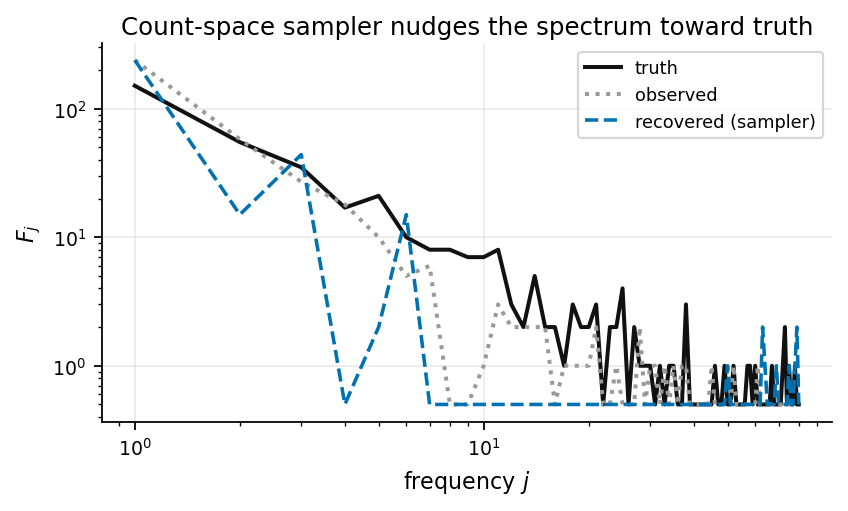

In [9]:
# --- 4b: spectrum recovery picture -------------------------------------------
jt = np.arange(1, min(len(s_true), 80) + 1)
fig, ax = plt.subplots(figsize=(5.4, 3.3))
ax.plot(jt, np.maximum(s_true[:len(jt)], 0.5), color=D.CB["truth"], lw=1.8, label="truth")
ax.plot(jt, np.maximum(s_obs[:len(jt)], 0.5), ":", color=D.CB["none"], lw=1.8, label="observed")
ax.plot(jt, np.maximum(s_rec[:len(jt)], 0.5), "--", color=D.CB["ours"], lw=1.6, label="recovered (sampler)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("frequency $j$"); ax.set_ylabel("$F_j$")
ax.set_title("Count-space sampler nudges the spectrum toward truth")
ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.savefig("fig_station4_spectrum.png", dpi=160); plt.show()

## What this verified

- **Station 1** — Binomial thinning is a clean noising channel; the FoF spectrum
  correctly excludes `F_0` (verified by the `assert` on the hand-built example).
- **Station 2** — The analytic posterior is closed-form and exact; the 90% set is
  well calibrated (per-type 95% coverage ≈ 0.95, calibration line near nominal),
  and the posterior-mean spectrum sits between the observed and the truth
  (a correct recovery check, computed directly rather than via re-noising).
- **Station 3** — The learned Thickener lowers `W1` below the no-thickening
  baseline on a tiny training run, confirming the forward/backward logic.
- **Station 4** — The count-space sampler's endpoint + closed-form reverse kernel
  runs, and the recovered spectrum moves toward the truth; the documented
  per-count overshoot under undertraining is expected and bounded by the clamp.

All of this is the same code that underlies the reported results
and backs the claims in the method section of the manuscript.